In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


48 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,67595,2996450582,Omnidirectional scene text detection has recei...,Detecting text in natural images is challengin...,0.2787,0.0344,0.1320,0.8386,0.8389,0.8387,2,9,9,97,False,96-100
1,87254,2995469692,Conventional cross-domain image-to-image trans...,Unsupervised domain adaptation seeks to transf...,0.3609,0.0615,0.1651,0.8315,0.8549,0.8430,4,9,9,54,False,51-55
2,133492,2981523288,"The revolution in computer hardware, especiall...","Recent advances in face synthesis, reenactment...",0.3324,0.0431,0.1501,0.8337,0.8433,0.8385,4,9,9,68,False,66-70


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


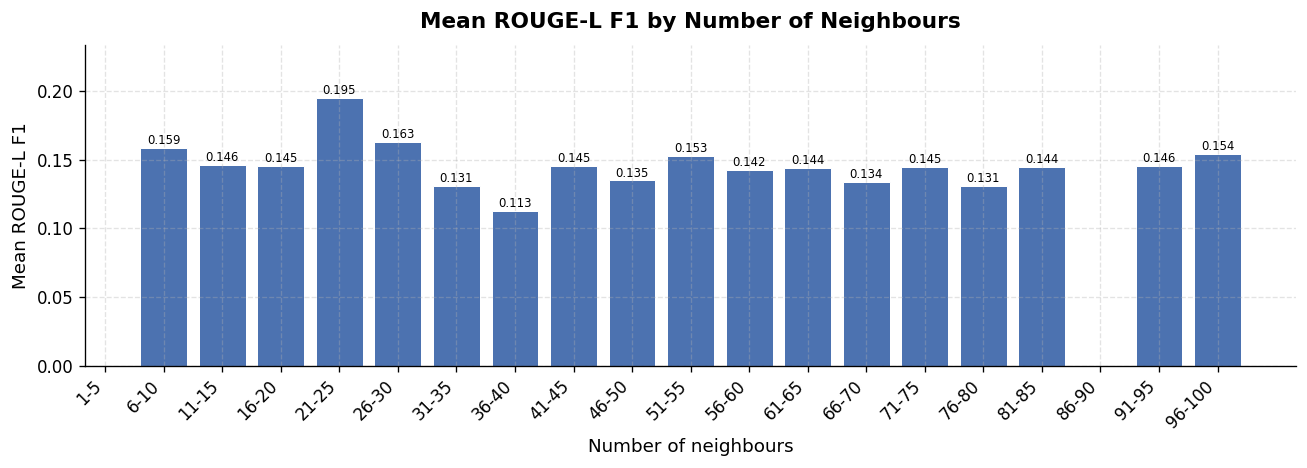

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

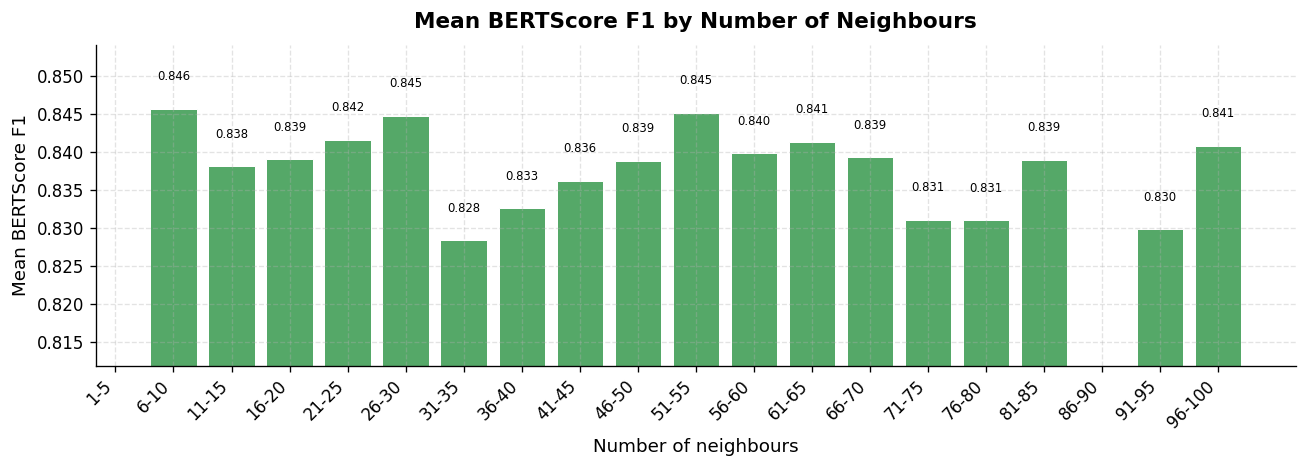

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

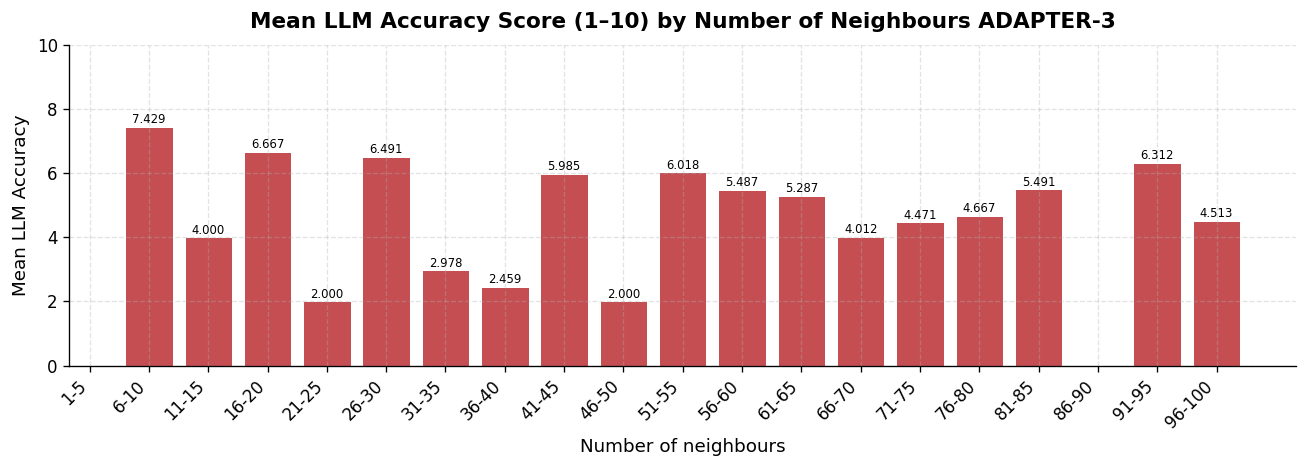

4.9375
4.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

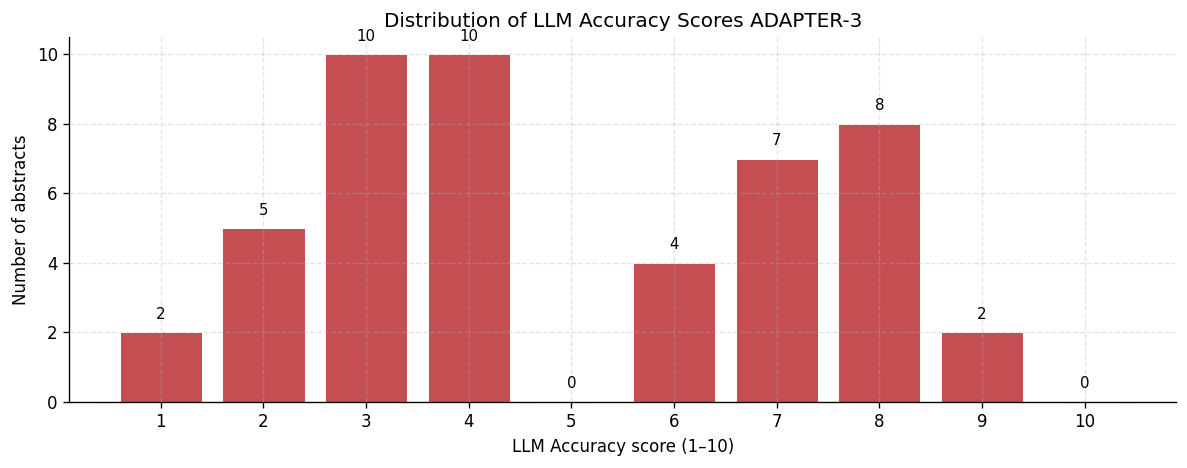

llm_accuracy
1      2
2      5
3     10
4     10
5      0
6      4
7      7
8      8
9      2
10     0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

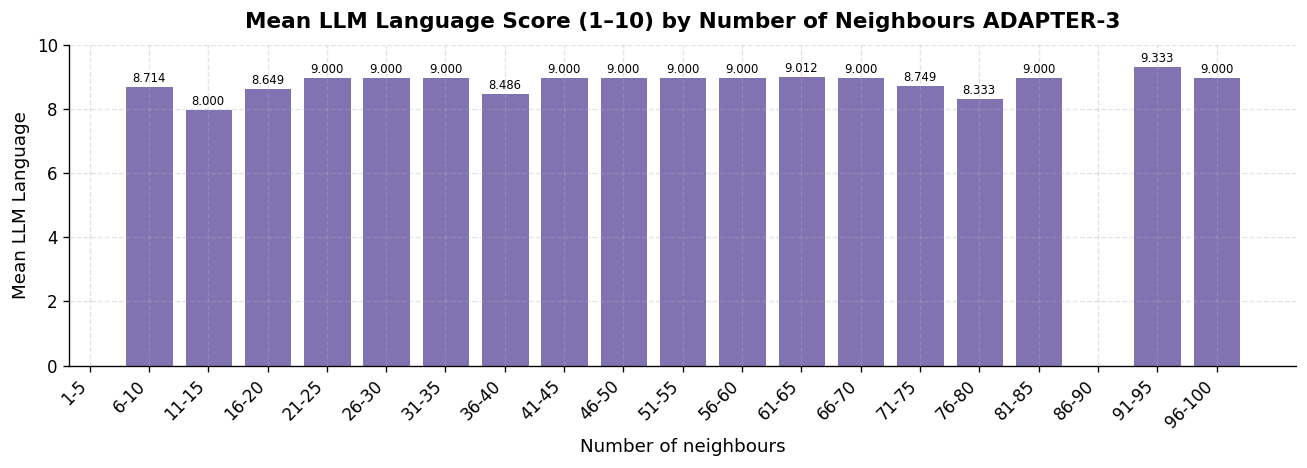

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

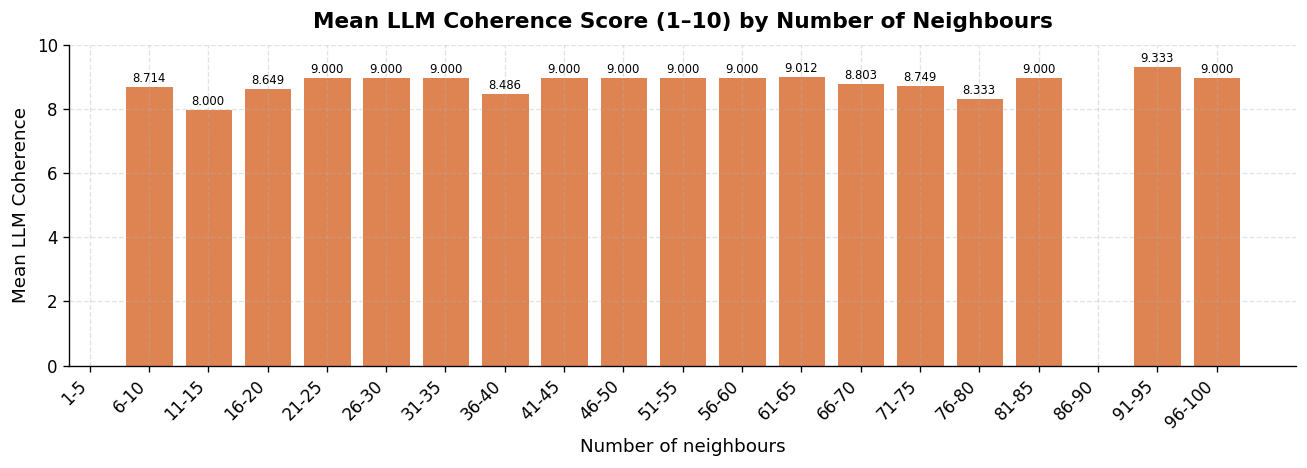

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

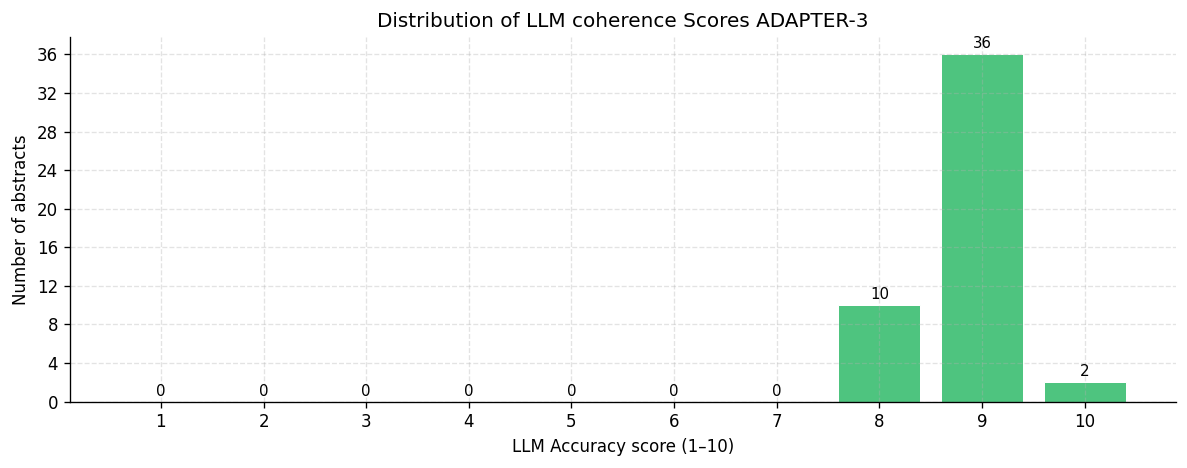

llm_coherence
1      0
2      0
3      0
4      0
5      0
6      0
7      0
8     10
9     36
10     2
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

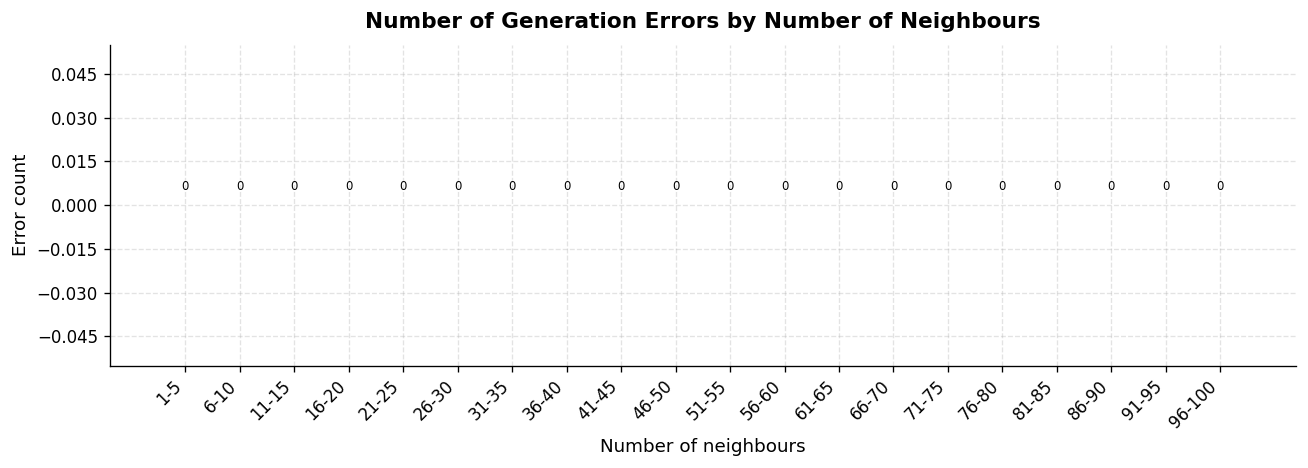

In [10]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

Pearson correlation (llm_accuracy vs llm_coherence):  0.3683
Spearman correlation (llm_accuracy vs llm_coherence): 0.3338
n = 48 rows


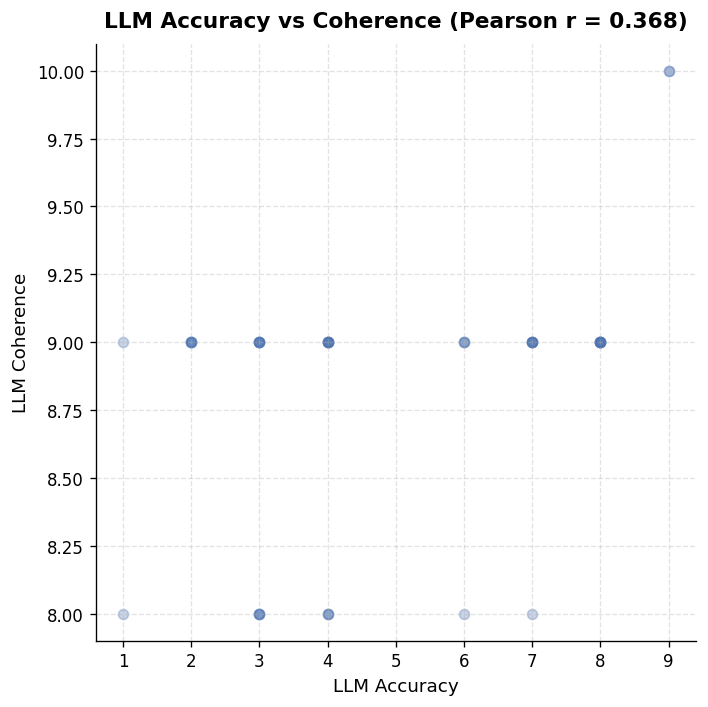

In [11]:
# ── Correlation between LLM Accuracy and LLM Coherence ───────────────────────
corr_df = df[['llm_accuracy', 'llm_coherence']].dropna()
pearson_r = corr_df['llm_accuracy'].corr(corr_df['llm_coherence'], method='pearson')
spearman_r = corr_df['llm_accuracy'].corr(corr_df['llm_coherence'], method='spearman')

print(f'Pearson correlation (llm_accuracy vs llm_coherence):  {pearson_r:.4f}')
print(f'Spearman correlation (llm_accuracy vs llm_coherence): {spearman_r:.4f}')
print(f'n = {len(corr_df)} rows')

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(corr_df['llm_accuracy'], corr_df['llm_coherence'], alpha=0.3, color='#4C72B0')
ax.set_xlabel('LLM Accuracy', fontsize=11)
ax.set_ylabel('LLM Coherence', fontsize=11)
ax.set_title(f'LLM Accuracy vs Coherence (Pearson r = {pearson_r:.3f})', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()


In [12]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_26493/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,106853,"Retrieve-and-edit based approaches to structured prediction, where structures associated with retrieved neighbors are edited to form new structures, have recently attracted increased interest. However, much recent work merely conditions on retrieved structures (e.g., in a sequence-to-sequence framework), rather than explicitly manipulating them. We show we can perform accurate sequence labeling by explicitly (and only) copying labels from retrieved neighbors. Moreover, because this copying is label-agnostic, we can achieve impressive performance in zero-shot sequence-labeling tasks. We additionally consider a dynamic programming approach to sequence labeling in the presence of retrieved neighbors, which allows for controlling the number of distinct (copied) segments used to form a prediction, and leads to both more interpretable and accurate predictions.","Sequence tagging systems have achieved strong results with bidirectional recurrent networks, character representations, and conditional random fields, but their performance often deteriorates when labeled data are scarce or the target domain and language differ from training conditions. Existing transfer-learning approaches address this limitation through recurrent hierarchies or auxiliary tasks, while contextual representations such as CoVe, ELMo, and BERT provide richer lexical and syntactic information but are not designed specifically for structured tagging decisions. This paper proposes a unified transfer-learning architecture for low-resource sequence labeling that combines a pre-trained bidirectional Transformer with subword representations and a CRF decoding layer. Unlike earlier BiLSTM-CNN models, the proposed system replaces recurrent encoding with self-attention and fine-tunes contextual representations jointly with the tagger; unlike conventional feature-based or cross-lingual methods, it requires no gazetteers, parallel corpora, or manually designed linguistic features. Experiments across named entity recognition and part-of-speech tagging datasets, including out-of-domain and low-resource settings, show consistent improvements over recurrent, static-embedding, and non-contextual baselines. The results demonstrate that pretrained bidirectional representations substantially improve transferability, while structured decoding remains valuable for enforcing globally coherent label sequences.",1
1,167449,"Given an artistic portrait, recovering the latent photorealistic face that preserves the subject’s identity is challenging because the facial details are often distorted or fully lost in artistic portraits. We develop an Identity-preserving Face Recovery from Portraits method that utilizes a Style Removal network (SRN) and a Discriminative Network (DN). Our SRN, composed of an autoencoder with residual block-embedded skip connections, is designed to transfer feature maps of stylized images to the feature maps of the corresponding photorealistic faces. Owing to the Spatial Transformer Network, SRN automatically compensates for misalignments of stylized portraits to output aligned realistic face images. To ensure the identity preservation, we promote the recovered and ground truth faces to share similar visual features via a distance measure which compares features of recovered and ground truth faces extracted from a pre-trained FaceNet network. DN has multiple convolutional and fully-connected layers, and its role is to enforce recovered faces to be similar to authentic faces. Thus, we can recover high-quality photorealistic faces from unaligned portraits while preserving the identity of the face in an image. By conducting extensive evaluations on a large-scale synthesized dataset and a hand-drawn sketch dataset, we demonstrate that our method achieves superior face recovery and attains state-of-the-art results. In addition, our method can recover photorealistic faces from unseen stylized portraits,

In [13]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_26493/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence


In [14]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 0 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      4.9375
Mean llm_accuracy (excluding 1,2): 4.9375


In [15]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


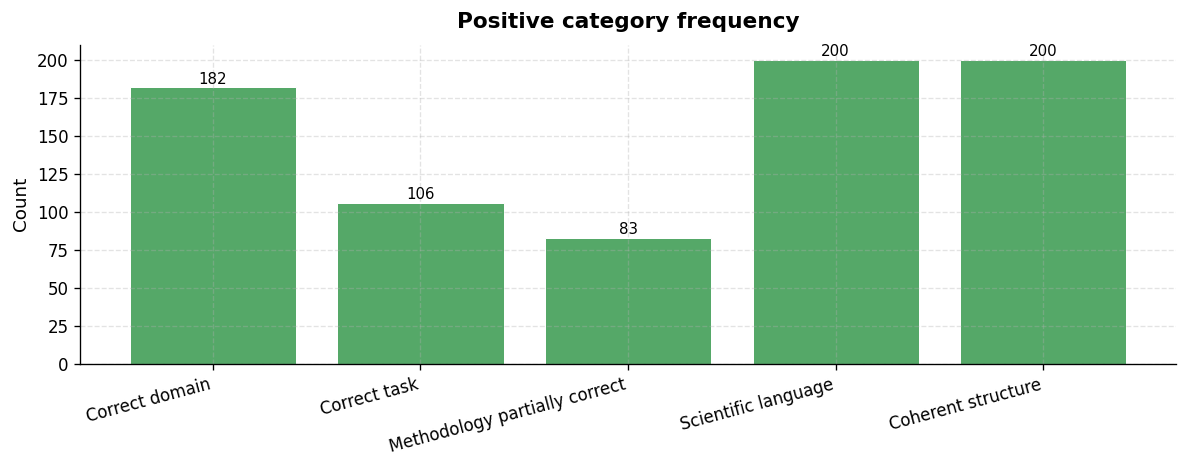

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()